# Sentiment140 Data Exploration

This notebook examines the Sentiment140 training dataset before model development. It describes the class balance, data quality, tweet length, social-media markers, and frequent terms that inform the later preprocessing decisions.

In [1]:
from collections import Counter
from pathlib import Path
import re

import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.max_colwidth", 180)
plt.style.use("seaborn-v0_8-whitegrid")
RANDOM_STATE = 42

## 1. Dataset and label definitions

The Sentiment140 training file has no header, so its six columns are named when it is loaded. Target values `0` and `4` represent negative and positive sentiment, respectively. The label mapping also includes `2` for neutral sentiment, although that class does not occur in this training file.

In [2]:
DATA_PATH = Path("data/training.1600000.processed.noemoticon.csv")
COLUMNS = ["target", "tweet_id", "date", "query", "user", "text"]
NROWS = None

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH.resolve()}")

df = pd.read_csv(DATA_PATH, names=COLUMNS, encoding="latin-1", nrows=NROWS)
df["sentiment"] = df["target"].map({0: "negative", 2: "neutral", 4: "positive"})
if df["sentiment"].isna().any():
    raise ValueError(f"Unknown target labels: {df.loc[df['sentiment'].isna(), 'target'].unique()}")

print(f"Rows: {len(df):,}")
print(f"Memory: {df.memory_usage(deep=True).sum() / 1024**2:,.1f} MB")
df.head()

Rows: 1,600,000
Memory: 655.3 MB


,target,tweet_id,date,query,user,text,sentiment
0,0,1467810369,Mon Apr 06 22:19:45 PDT 2009,NO_QUERY,_TheSpecialOne_,"@switchfoot http://twitpic.com/2y1zl - Awww, that's a bummer. You shoulda got David Carr of Third Day to do it. ;D",negative
1,0,1467810672,Mon Apr 06 22:19:49 PDT 2009,NO_QUERY,scotthamilton,is upset that he can't update his Facebook by texting it... and might cry as a result School today also. Blah!,negative
2,0,1467810917,Mon Apr 06 22:19:53 PDT 2009,NO_QUERY,mattycus,@Kenichan I dived many times for the ball. Managed to save 50% The rest go out of bounds,negative
3,0,1467811184,Mon Apr 06 22:19:57 PDT 2009,NO_QUERY,ElleCTF,my whole body feels itchy and like its on fire,negative
4,0,1467811193,Mon Apr 06 22:19:57 PDT 2009,NO_QUERY,Karoli,"@nationwideclass no, it's not behaving at all. i'm mad. why am i here? because I can't see you all over there.",negative


## 2. Structure and label distribution

In [3]:
df.info()
print("\nTargets:", sorted(df["target"].unique()))
print("Unmapped targets:", df["sentiment"].isna().sum())
print("Query values:", df["query"].unique())

<class 'pandas.DataFrame'>
RangeIndex: 1600000 entries, 0 to 1599999
Data columns (total 7 columns):
 #   Column     Non-Null Count    Dtype
---  ------     --------------    -----
 0   target     1600000 non-null  int64
 1   tweet_id   1600000 non-null  int64
 2   date       1600000 non-null  str  
 3   query      1600000 non-null  str  
 4   user       1600000 non-null  str  
 5   text       1600000 non-null  str  
 6   sentiment  1600000 non-null  str  
dtypes: int64(2), str(5)
memory usage: 85.4 MB

Targets: [np.int64(0), np.int64(4)]
Unmapped targets: 0
Query values: <StringArray>
['NO_QUERY']
Length: 1, dtype: str


,count,percent
sentiment,,
negative,800000,50.0
positive,800000,50.0


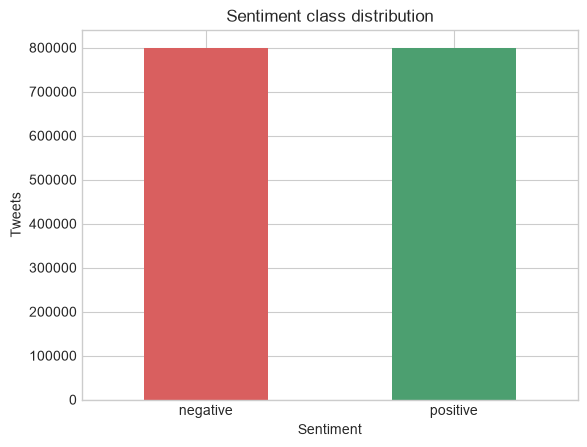

In [4]:
sentiment_order = [label for label in ["negative", "neutral", "positive"] if label in df["sentiment"].values]
sentiment_colors = {"negative": "#d95f5f", "neutral": "#d9a441", "positive": "#4c9f70"}
class_counts = (
    df["sentiment"]
    .value_counts()
    .reindex(sentiment_order, fill_value=0)
)

display(pd.DataFrame({
    "count": class_counts,
    "percent": (class_counts / len(df) * 100).round(2),
}))

ax = class_counts.plot.bar(
    color=[sentiment_colors[label] for label in sentiment_order],
    rot=0,
    title="Sentiment class distribution",
)
ax.set(xlabel="Sentiment", ylabel="Tweets")
plt.show()

**Finding:** The training file has 1,600,000 tweets, split evenly between negative and positive (800,000 each). There are no neutral (`2`) rows or unmapped labels. The `query` field contains only `NO_QUERY`, so it does not distinguish these records.

## 3. Data quality

Missing values, blank text, duplicate records, and repeated tweet text were examined. Repeated text matters for evaluation because identical examples in different data splits could make performance appear stronger than it is.

In [5]:
quality = pd.Series({
    "missing cells": int(df.isna().sum().sum()),
    "duplicate rows": int(df.duplicated().sum()),
    "duplicate tweet IDs": int(df["tweet_id"].duplicated().sum()),
    "duplicate text values": int(df["text"].duplicated().sum()),
    "blank text values": int(df["text"].str.strip().eq("").sum()),
}, name="count")
display(quality.to_frame())

conflicting_text = df.groupby("text", sort=False)["sentiment"].nunique().gt(1).sum()
print(f"Texts with conflicting labels: {conflicting_text:,}")

,count
missing cells,0
duplicate rows,0
duplicate tweet IDs,1685
duplicate text values,18534
blank text values,0


Texts with conflicting labels: 2,225


In [6]:
duplicate_text_rows = (
    df[df.duplicated("text", keep=False)]
    .sort_values("text")
    [["sentiment", "text"]]
)
output_path = Path("data/duplicate_text_rows.csv")
duplicate_text_rows.to_csv(output_path, index=False)
print(f"Exported {len(duplicate_text_rows):,} rows to {output_path}")
print(f"Distinct repeated texts: {duplicate_text_rows['text'].nunique():,}")
conflicting_labels = duplicate_text_rows.groupby("text")["sentiment"].nunique().gt(1).sum()
print(f"Repeated texts with conflicting labels: {conflicting_labels:,}")
duplicate_text_rows.head(10)

Exported 26,968 rows to data/duplicate_text_rows.csv
Distinct repeated texts: 8,434
Repeated texts with conflicting labels: 2,225


,sentiment,text
271472,negative,David must be hospitalized for five days end of July (palatine tonsils). I will probably never see Katie in concert.
271505,negative,David must be hospitalized for five days end of July (palatine tonsils). I will probably never see Katie in concert.
1132076,positive,bathroom is clean..... now on to more enjoyable tasks......
1132074,positive,bathroom is clean..... now on to more enjoyable tasks......
540159,negative,#IMISSCATH #IMISSCATH #IMISSCATH #IMISSCATH #IMISSCATH #IMISSCATH #IMISSCATH #IMISSCATH #IMISSCATH #IMISSCATH #IMISSCATH #IMISSCATH
540173,negative,#IMISSCATH #IMISSCATH #IMISSCATH #IMISSCATH #IMISSCATH #IMISSCATH #IMISSCATH #IMISSCATH #IMISSCATH #IMISSCATH #IMISSCATH #IMISSCATH
1357123,positive,#seb-day #seb-day #seb-day #seb-day #seb-day #seb-day #seb-day #seb-day #seb-day #seb-day #seb-day #seb-day #seb-day #seb-day
1364947,positive,#seb-day #seb-day #seb-day #seb-day #seb-day #seb-day #seb-day #seb-day #seb-day #seb-day #seb-day #seb-day #seb-day #seb-day
287201,negative,*tear*
331063,negative,*tear*


### Conflicting labels among repeated texts

The same text can sometimes have different sentiment labels. These cases were examined separately because text alone cannot resolve the disagreement.

In [7]:
label_counts = df.groupby(["text", "sentiment"]).size().unstack(fill_value=0)
conflict_counts = label_counts.loc[label_counts.gt(0).sum(axis=1).gt(1)].copy()
conflict_counts["total"] = conflict_counts.sum(axis=1)
display(conflict_counts.sort_values("total", ascending=False).head(10))

sentiment,negative,positive,total
text,,,
Good morning,2,110,112
Goodnight,3,82,85
my tummy hurts,80,1,81
at work,70,7,77
goodnight,8,62,70
At work,60,7,67
Good Morning,1,63,64
my head hurts,53,1,54
homework,52,1,53


**Finding:** There are no missing values, blank tweet texts, or completely identical rows. There are 1,685 repeated tweet IDs. Exact text repeats in 26,968 rows across 8,434 distinct texts; 2,225 of those texts have conflicting sentiment labels. Conflict examples include short phrases such as `Good morning` and `at work`, whose sentiment can depend on context. The raw rows remain available in this exploration, while duplicate handling is applied during preprocessing.

## 4. Text lengths and social-media markers

In [8]:
df["character_count"] = df["text"].str.len()
df["word_count"] = df["text"].str.findall(r"\b\w+\b").str.len()
df["has_url"] = df["text"].str.contains(r"https?://|www\.", case=False, regex=True)
df["has_mention"] = df["text"].str.contains(r"@\w+", regex=True)
df["has_hashtag"] = df["text"].str.contains(r"#\w+", regex=True)

df.groupby("sentiment")[["character_count", "word_count"]].describe(
    percentiles=[0.25, 0.5, 0.75, 0.95]
)

character_count                                                \
                    count       mean        std  min   25%   50%    75%   
sentiment                                                                 
negative         800000.0  74.301790  36.743260  6.0  44.0  70.0  104.0   
positive         800000.0  73.878433  36.135274  6.0  44.0  69.0  103.0   

                        word_count                                             \
             95%    max      count       mean       std  min  25%   50%   75%   
sentiment                                                                       
negative   136.0  359.0   800000.0  14.222247  7.412073  1.0  8.0  13.0  20.0   
positive   136.0  374.0   800000.0  13.444387  7.210564  1.0  8.0  12.0  19.0   

                        
            95%    max  
sentiment               
negative   27.0  112.0  
positive   26.0  119.0

In [9]:
marker_rates = df.groupby("sentiment")[["has_url", "has_mention", "has_hashtag"]].mean().mul(100).round(2)
marker_rates.columns = ["URL (%)", "mention (%)", "hashtag (%)"]
marker_rates

,URL (%),mention (%),hashtag (%)
sentiment,,,
negative,3.19,37.61,1.90
positive,6.39,54.71,2.58


**Finding:** Lengths are similar across classes: the median negative tweet is 70 characters and 13 words; the median positive tweet is 69 characters and 12 words. The largest values are much higher than the 95th percentiles, so unusually long texts are worth checking later. Positive tweets contain URLs (6.39% vs 3.19%), mentions (54.71% vs 37.61%), and hashtags (2.58% vs 1.90%) more often than negative tweets. These are descriptive associations, not evidence that the markers cause sentiment.

## 5. Random examples and label quality

In [10]:
for sentiment in sentiment_order:
    print(f"\n{sentiment.upper()} EXAMPLES")
    display(
        df.loc[df["sentiment"].eq(sentiment), ["text"]]
        .sample(min(5, class_counts[sentiment]), random_state=RANDOM_STATE)
        .reset_index(drop=True)
    )


NEGATIVE EXAMPLES


,text
0,@xnausikaax oh no! where did u order from? that's horrible
1,A great hard training weekend is over. a couple days of rest and lets do it again! Lots of computer time to put in now
2,"Right, off to work Only 5 hours to go until I'm free xD"
3,I am craving for japanese food
4,Jean Michel Jarre concert tomorrow gotta work 7-3 before though



POSITIVE EXAMPLES


,text
0,Is lookin 4ward to a long weekend really dont want to go to work 2day tho =[ x
1,#myweakness Is music and i live to meet the people who make it
2,figured out the Internet on my new iPod
3,@hillsongunited can't wait to worship with you guys tonight. it'll be so much fun
4,@sillybeggar Congrats James !! I'm sure the book is going to be a huge success


## 6. Frequent terms by sentiment

Term frequencies provide a descriptive view of the two classes. They are calculated on a sample to keep exploration practical and do not define the later tokenization pipeline.

In [11]:
STOP_WORDS = {
    "a", "an", "and", "are", "as", "at", "be", "but", "by", "for",
    "from", "i", "in", "is", "it", "me", "my", "of", "on", "or",
    "so", "that", "the", "this", "to", "was", "with", "you", "your",
    "im", "its", "just",
}
TOKEN_RE = re.compile(r"[a-z][a-z']+")

def common_terms(texts, n=20):
    counts = Counter()
    for text in texts:
        cleaned = re.sub(r"https?://\S+|www\.\S+|@\w+", " ", text.lower())
        counts.update(token for token in TOKEN_RE.findall(cleaned) if token not in STOP_WORDS)
    return pd.DataFrame(counts.most_common(n), columns=["term", "count"])

term_sample = df.sample(min(200_000, len(df)), random_state=RANDOM_STATE)
for sentiment in sentiment_order:
    terms = common_terms(term_sample.loc[term_sample["sentiment"].eq(sentiment), "text"])
    display(f"{sentiment.title()} tweets", terms)

'Negative tweets'

,term,count
0,have,10292
1,not,9362
2,i'm,9343
3,no,6712
4,now,6639
5,up,6076
6,get,5762
7,work,5684
8,go,5616
9,out,5498


'Positive tweets'

,term,count
0,have,8005
1,good,7827
2,i'm,7132
3,love,5962
4,quot,5887
5,day,5874
6,up,5250
7,now,5209
8,all,4920
9,out,4831


**Finding:** In the 200,000-tweet sample, `not` and `no` are frequent in negative tweets, while `good`, `love`, `lol`, and `thanks` are frequent in positive tweets. Many words, including `have` and `i'm`, occur in both classes, so frequency alone does not make a word a reliable predictor. The frequent `quot` token likely comes from an HTML entity such as `&quot;`, motivating HTML-entity decoding during preprocessing.